# 06 – Part 3 (Track A): results in pictures

`05_part3_mmr.ipynb` introduced MMR re-ranking of our Part 2 ALS model (the best test NDCG@10 in Part 2, 0.2301),
compared four values of λ on validation, chose λ = 0.7 and checked it on test. This notebook shows the full
evaluation built on the same code (`mmr_rerank` and the metric functions in `src/part3_mmr.py`): all λ from 1 to 0
on both splits, paired tests, who pays, and the size of the candidate pool.

- **Item representation:** the genres of a movie (18 MovieLens genres).
- **Item distance:** **1 − Jaccard similarity** of the genre sets of two movies, i.e. 1 − |shared genres| / |genres of
  either movie|. The same distance is used inside MMR and in intra-list diversity (ILD).
- **MMR:** from the ALS top-100, pick 10 movies one by one, each time the movie with the highest
  λ · relevance − (1 − λ) · max similarity to the movies already picked. Relevance is the ALS score
  min-max scaled to [0, 1] within the 100 candidates. λ = 1 is plain ALS, λ = 0 only maximises diversity.
- **Protocol:** as in notebook 05 and Part 2. λ is chosen on **validation** (ALS trained on train, validation users
  with training history); the frontier we report is on **test** (ALS trained on train + validation, all 1,188 test
  users, cold users included). The λ = 1, 0.7, 0.5 and 0.3 numbers are the same as in notebook 05.

This notebook trains nothing: it only reads the CSVs that
`python -m src.part3_analysis --data-dir data/ml-1m` (about 2 minutes) wrote to `results/part3_analysis/`.
The figures are saved to `results/part3_analysis/figures/`.

| Section | Question |
|---|---|
| 1. Frontier | What does diversity cost in accuracy, for every λ? Where is the curve flat and where does it turn? |
| 2. Is the loss real? | Which accuracy losses are bigger than the noise (paired tests)? |
| 3. Beyond accuracy | What happens to coverage, Gini, calibration and popularity? |
| 4. Who pays | Which users lose accuracy, and which genres gain or lose exposure? |
| 5. Candidate pool | Is the top-100 pool the reason coverage does not improve? (notebook 05's open question) |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results" / "part3_analysis"
FIGURES = RESULTS / "figures"
FIGURES.mkdir(exist_ok=True)

ALS = "#eda100"         # the ALS colour from notebooks 03 and 04 (test results)
VALIDATION = "#8c8c8c"  # validation results in grey
CHOSEN = 0.7            # chosen operating point (part3.chosen_lambda in config.yaml)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "lines.linewidth": 2,
                     "axes.axisbelow": True})


def save(fig, name):
    # Saves a figure for the report.
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")


frontier = pd.read_csv(RESULTS / "part3_frontier.csv")
val = frontier[frontier["split"] == "validation"].set_index("lambda")
test = frontier[frontier["split"] == "test"].set_index("lambda")
tests = pd.read_csv(RESULTS / "part3_paired_tests.csv")
who = pd.read_csv(RESULTS / "part3_who_pays.csv")
genres = pd.read_csv(RESULTS / "part3_genre_exposure.csv")
pool = pd.read_csv(RESULTS / "part3_pool_size.csv")
print(f"{len(val)} lambdas, {int(val['users'].iloc[0])} validation users, {int(test['users'].iloc[0])} test users")

11 lambdas, 492 validation users, 1188 test users


## 1. The accuracy–diversity frontier

Every point is one λ (Lecture 5.1, slide 13). Accuracy is NDCG@10, diversity is the mean ILD of the top-10 lists.
Validation and test have different NDCG levels (validation covers only one month and fewer users), so we
compare λ values **within** a split, not across splits.

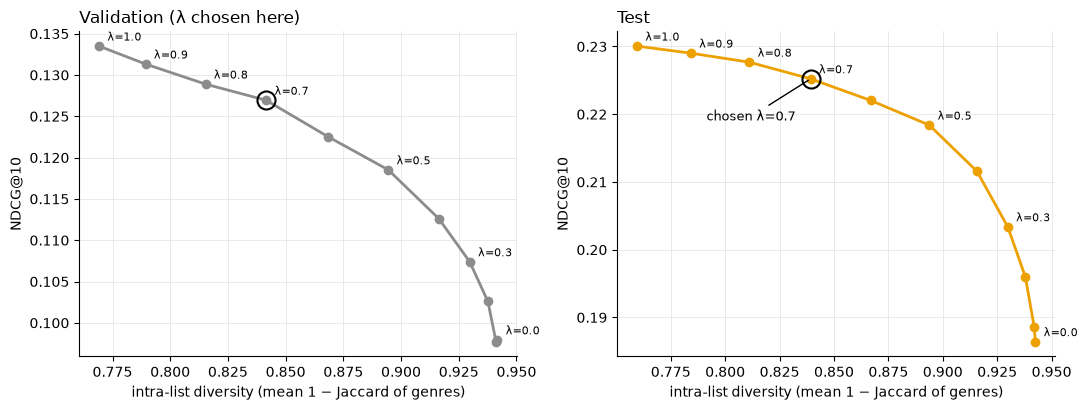

Test: NDCG lost per 0.1 of ILD gained, for each step of λ (from the λ above):
lambda
0.9    0.0042
0.8    0.0050
0.7    0.0087
0.6    0.0116
0.5    0.0135
0.4    0.0311
0.3    0.0579
0.2    0.0914
0.1    0.1819
0.0    0.4065


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, data, color) in zip(axes, [("Validation (λ chosen here)", val, VALIDATION), ("Test", test, ALS)]):
    ax.plot(data["ild"], data["ndcg"], marker="o", color=color, markersize=6)
    for lam, row in data.iterrows():
        if lam in (1.0, 0.9, 0.8, 0.7, 0.5, 0.3, 0.0):
            ax.annotate(f"λ={lam:.1f}", (row["ild"], row["ndcg"]), xytext=(6, 4),
                        textcoords="offset points", fontsize=8)
    ax.plot(data.loc[CHOSEN, "ild"], data.loc[CHOSEN, "ndcg"], "o", markersize=13,
            markerfacecolor="none", markeredgecolor="black", markeredgewidth=1.5)
    ax.set_xlabel("intra-list diversity (mean 1 − Jaccard of genres)")
    ax.set_ylabel("NDCG@10")
    ax.set_title(name, loc="left")
axes[1].annotate("chosen λ=0.7", (test.loc[CHOSEN, "ild"], test.loc[CHOSEN, "ndcg"]), xytext=(-75, -30),
                 textcoords="offset points", fontsize=9, arrowprops={"arrowstyle": "-", "color": "black"})
plt.tight_layout()
save(fig, "frontier")
plt.show()

slope = test[["ndcg", "ild"]].sort_index(ascending=False).diff().dropna()
slope["NDCG lost per 0.1 ILD gained"] = -slope["ndcg"] / slope["ild"] * 0.1
print("Test: NDCG lost per 0.1 of ILD gained, for each step of λ (from the λ above):")
print(slope["NDCG lost per 0.1 ILD gained"].round(4).to_string())

**What it shows**
- **Shallow at the top (λ = 1 → 0.7):** ILD rises from 0.760 to 0.839 (+10%) while test NDCG@10 drops only from
  0.2301 to 0.2252 (−2.1%). Each 0.1 of ILD costs 0.004–0.009 NDCG.
- **Steeper in the middle (λ = 0.6 → 0.5):** about 0.012–0.014 NDCG per 0.1 of ILD.
- **The curve turns at λ ≈ 0.4:** from there each step down costs about twice as much as the previous one
  (0.03, 0.06, 0.09, 0.18, 0.41 NDCG per 0.1 ILD), because ILD saturates around 0.94 (a top 10 of almost
  entirely different genres) while the movies MMR pulls in come from further and further down the ALS list.
  Between λ = 0.1 and 0 almost nothing changes any more.
- The validation and test curves have the same shape, so the λ chosen on validation transfers to test.
- **Why λ = 0.7 (the choice of notebook 05 holds on the finer sweep):** on the validation curve the NDCG cost per
  unit of ILD about doubles after λ = 0.7 (0.008 → 0.016 per 0.1 ILD), and by λ = 0.7 most of the calibration gain
  is already there (section 3). It is a judgement on the validation frontier, made before looking at test.

## 2. Is the accuracy loss real?

Paired t-test on per-user NDCG@10 of every λ against λ = 1 (plain ALS), on the same 1,188 test users,
Holm-corrected over the 10 comparisons. The error bars are 95% confidence intervals of the mean per-user
difference. The ILD gain is shown for comparison (users with a list, i.e. without the 29 cold users).

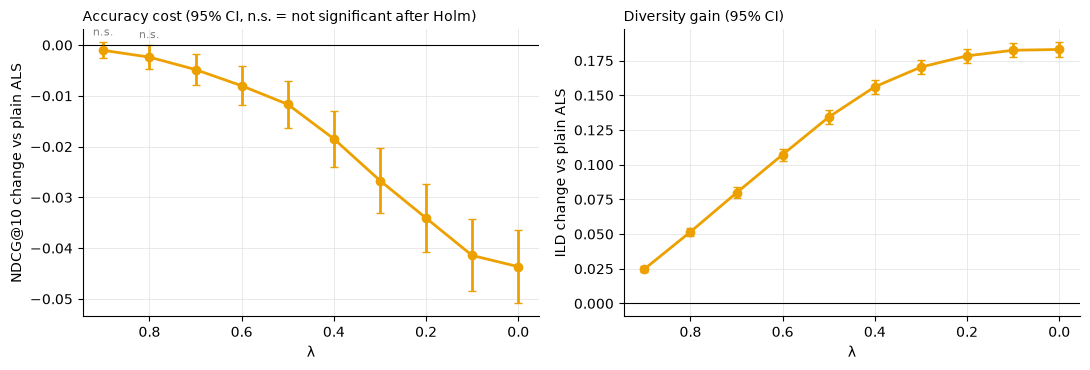

,mean_difference,difference_ci95_low,difference_ci95_high,relative_change,p_value_holm
lambda,,,,,
0.9,-0.0010,-0.0026,0.0005,-0.0045,0.1932
0.8,-0.0024,-0.0048,0.0000,-0.0103,0.1010
0.7,-0.0048,-0.0079,-0.0017,-0.0210,0.0073
0.6,-0.0080,-0.0119,-0.0042,-0.0348,0.0002
0.5,-0.0117,-0.0163,-0.0070,-0.0507,0.0000
0.4,-0.0185,-0.0240,-0.0130,-0.0803,0.0000
0.3,-0.0267,-0.0330,-0.0204,-0.1160,0.0000
0.2,-0.0341,-0.0408,-0.0273,-0.1481,0.0000
0.1,-0.0414,-0.0485,-0.0344,-0.1801,0.0000


In [3]:
nd = tests[tests["metric"] == "ndcg"].set_index("lambda").sort_index(ascending=False)
il = tests[tests["metric"] == "ild"].set_index("lambda").sort_index(ascending=False)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, data, label in [(ax1, nd, "NDCG@10 change vs plain ALS"), (ax2, il, "ILD change vs plain ALS")]:
    err = [data["mean_difference"] - data["difference_ci95_low"], data["difference_ci95_high"] - data["mean_difference"]]
    ax.errorbar(data.index, data["mean_difference"], yerr=err, fmt="o-", color=ALS, capsize=3, markersize=6)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel(label)
    ax.set_xlabel("λ")
ax1.invert_xaxis()  # the axes share x, so inverting one inverts both
for lam, row in nd.iterrows():
    if not row["significant_at_0_05_holm"]:
        ax1.annotate("n.s.", (lam, row["difference_ci95_high"]), xytext=(0, 5),
                     textcoords="offset points", ha="center", fontsize=8, color="grey")
ax1.set_title("Accuracy cost (95% CI, n.s. = not significant after Holm)", loc="left", fontsize=10)
ax2.set_title("Diversity gain (95% CI)", loc="left", fontsize=10)
plt.tight_layout()
save(fig, "paired_tests")
plt.show()

nd[["mean_difference", "difference_ci95_low", "difference_ci95_high", "relative_change", "p_value_holm"]].round(4)

**What it shows**
- λ = 0.9 and 0.8 lose no NDCG that we can distinguish from noise (Holm p = 0.19 and 0.10).
- λ = 0.7 is the first setting with a significant loss: −0.0048 NDCG@10 [−0.0079, −0.0017], −2.1%,
  Holm p = 0.007. The loss is small but real, so we report it as a cost, not as "no change".
- The ILD gain is significant at every λ, and its CI is much narrower than the NDCG one: the re-ranking
  changes diversity for every user, but it changes accuracy only for users whose hits move in or out of the top 10.

## 3. Coverage, Gini, calibration and popularity

The four metrics of Lecture 5.1, slide 7, plus the share of recommendation slots that go to the 20% most-rated
movies (the popularity split from Part 2). Calibration error is the squared Jensen–Shannon distance (base 2,
between 0 and 1) between the genre mix of the movies a user liked in the training history and the genre mix of
their top 10, as in notebook 05 (every genre of a movie counts once). Lower is better.

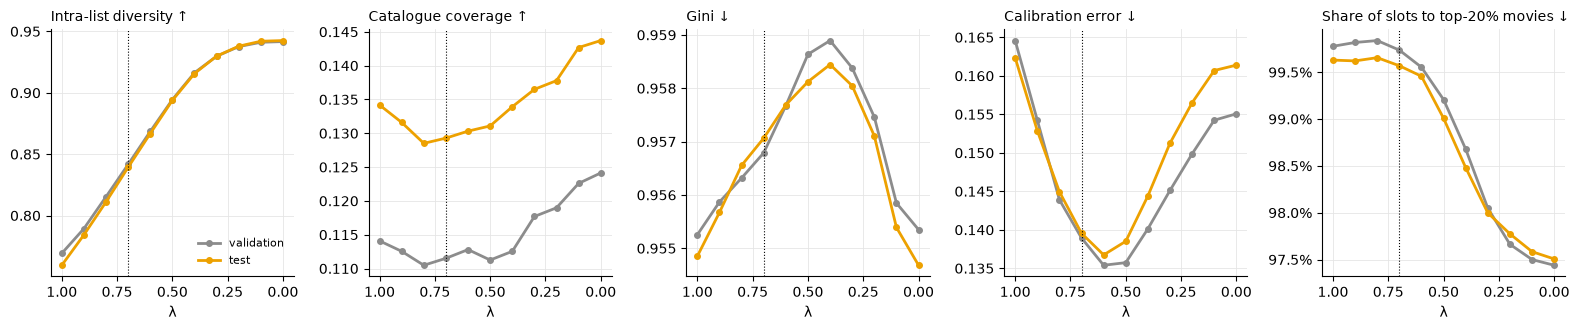

,precision,recall,ndcg,ild,coverage,gini,calibration_error,popular_share
lambda,,,,,,,,
1.0,0.2044,0.0734,0.2301,0.7595,0.1342,0.9549,0.1623,0.9963
0.9,0.2030,0.0720,0.2290,0.7843,0.1316,0.9557,0.1529,0.9962
0.8,0.2012,0.0706,0.2277,0.8111,0.1285,0.9566,0.1449,0.9965
0.7,0.1992,0.0695,0.2252,0.8393,0.1293,0.9571,0.1395,0.9957
0.6,0.1952,0.0672,0.2220,0.8668,0.1303,0.9577,0.1367,0.9946
0.5,0.1912,0.0651,0.2184,0.8938,0.1311,0.9581,0.1385,0.9901
0.4,0.1833,0.0622,0.2116,0.9157,0.1339,0.9584,0.1444,0.9848
0.3,0.1747,0.0578,0.2034,0.9299,0.1365,0.9580,0.1513,0.9800
0.2,0.1663,0.0545,0.1960,0.9379,0.1378,0.9571,0.1565,0.9777


In [4]:
panels = [("ild", "Intra-list diversity ↑"), ("coverage", "Catalogue coverage ↑"), ("gini", "Gini ↓"),
          ("calibration_error", "Calibration error ↓"), ("popular_share", "Share of slots to top-20% movies ↓")]
fig, axes = plt.subplots(1, 5, figsize=(16, 3.4))
for ax, (metric, title) in zip(axes, panels):
    ax.plot(val.index, val[metric], marker="o", markersize=4, color=VALIDATION, label="validation")
    ax.plot(test.index, test[metric], marker="o", markersize=4, color=ALS, label="test")
    ax.axvline(CHOSEN, color="black", linewidth=0.8, linestyle=":")
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("λ")
    ax.invert_xaxis()
axes[0].legend(frameon=False, fontsize=8)
axes[4].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
plt.tight_layout()
save(fig, "beyond_accuracy")
plt.show()

test[["precision", "recall", "ndcg", "ild", "coverage", "gini", "calibration_error", "popular_share"]].round(4)

**What it shows**
- **Calibration is U-shaped.** Plain ALS over-represents the dominant genres of a user's history, so some
  diversification moves the genre mix closer to the user's own: test calibration error falls from 0.162 to
  0.140 at λ = 0.7 (−14%); the minimum is 0.137 at λ = 0.6 on test (0.135 at 0.6 on validation). Below that MMR
  starts adding genres the user does not watch, and at λ = 0.1–0 calibration is back at the plain-ALS level
  (0.161, not significantly different).
- **Coverage and Gini barely move and are not monotonic.** Coverage first falls (0.134 → 0.129 at λ = 0.7) and
  only exceeds plain ALS below λ = 0.4; Gini stays at 0.955–0.958. MMR diversifies *within* each list, but
  every user's diversified list is built from the same popular movies, so exposure across the catalogue does
  not spread out.
- **Popularity bias is untouched.** 99.6% of all recommendation slots go to the top-20% most-rated movies with
  plain ALS, 99.6% at λ = 0.7 and still 97.5% at λ = 0. Genre diversity is not popularity diversity: a
  diversified list swaps a popular drama for a popular sci-fi movie, not for a long-tail one.

## 4. Who pays

### 4a. Users

The change in NDCG@10 from plain ALS to λ = 0.7 per user group (95% CI of the mean per-user difference).
Activity groups are the ones from Part 2 (median 86 ratings in train + validation). Taste breadth is new:
the entropy of the genre distribution of the movies a user liked, split at the median (3.33 bits).

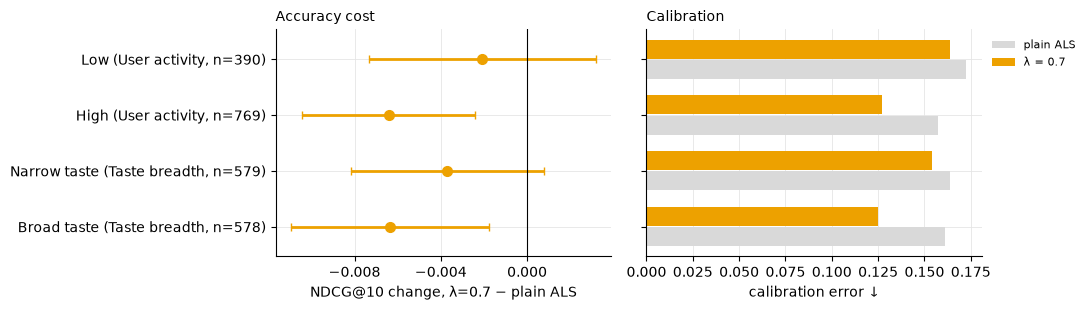

,group,definition,users,ndcg_difference,ndcg_difference_ci95_low,ndcg_difference_ci95_high,ndcg_base,ndcg_mmr,ild_base,ild_mmr,calibration_error_base,calibration_error_mmr,popular_share_base,popular_share_mmr
0,Cold,0 history ratings,29,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
1,Low,<= 86 history ratings (median),390,-0.0021,-0.0073,0.0032,0.2242,0.2221,0.7367,0.8180,0.1726,0.1639,0.9951,0.9949
2,High,> 86 history ratings,769,-0.0064,-0.0104,-0.0024,0.2417,0.2353,0.7711,0.8501,0.1572,0.1272,0.9969,0.9961
3,Narrow taste,genre entropy <= 3.33 bits (median),579,-0.0037,-0.0082,0.0008,0.2210,0.2173,0.7283,0.8182,0.1637,0.1542,0.9993,0.9993
4,Broad taste,genre entropy > 3.33 bits,578,-0.0064,-0.0110,-0.0018,0.2515,0.2451,0.7905,0.8600,0.1610,0.1249,0.9964,0.9952


In [5]:
w = who[who["group"] != "Cold"].iloc[::-1].reset_index(drop=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
y = np.arange(len(w))
err = [w["ndcg_difference"] - w["ndcg_difference_ci95_low"], w["ndcg_difference_ci95_high"] - w["ndcg_difference"]]
ax1.errorbar(w["ndcg_difference"], y, xerr=err, fmt="o", color=ALS, capsize=3, markersize=7)
ax1.axvline(0, color="black", linewidth=0.8)
ax1.set_yticks(y, [f"{g} ({d}, n={n})" for g, d, n in zip(w["group"], w["dimension"], w["users"])])
ax1.xaxis.set_major_locator(plt.MaxNLocator(5))
ax1.set_xlabel("NDCG@10 change, λ=0.7 − plain ALS")
ax1.set_title("Accuracy cost", loc="left", fontsize=10)
ax2.barh(y - 0.18, w["calibration_error_base"], height=0.34, color="#d9d9d9", label="plain ALS")
ax2.barh(y + 0.18, w["calibration_error_mmr"], height=0.34, color=ALS, label="λ = 0.7")
ax2.set_xlabel("calibration error ↓")
ax2.set_title("Calibration", loc="left", fontsize=10)
ax2.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
save(fig, "who_pays_users")
plt.show()

who.drop(columns=["dimension"]).round(4)

**What it shows**
- **Heavy users and users with broad taste pay** the accuracy cost: −0.0064 NDCG for high-activity users and
  −0.0064 for broad-taste users, both with CIs below zero. For low-activity and narrow-taste users the loss
  is not distinguishable from zero.
- **The same users also get the benefit:** broad-taste and high-activity users gain the most calibration
  (broad: 0.161 → 0.125, high activity: 0.157 → 0.127), while narrow-taste users only go from 0.164 to 0.154. For a user who mostly likes one or two
  genres, a list with more genres does not match their history better.
- **Cold users (29) are untouched:** ALS has no list for them with or without MMR (NDCG 0), as in Part 2.

### 4b. Genres (the item side)

Share of all recommendation slots that goes to each genre, with plain ALS, with λ = 0.7 and with λ = 0,
compared with the genre's share of the catalogue. Counted like the calibration error (every genre of a movie once).

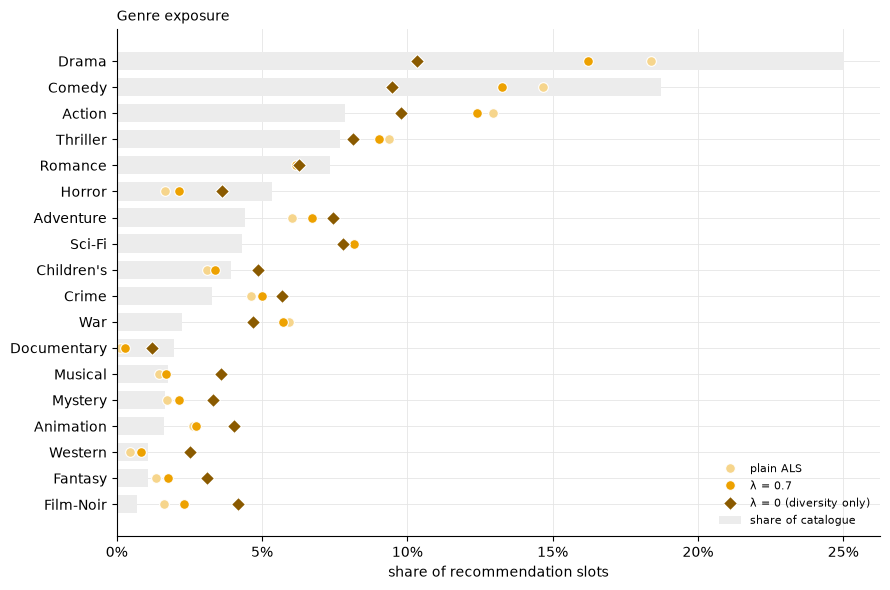

,catalogue,lambda=1.0,lambda=0.7,lambda=0.0
genre,,,,
Drama,25.0,18.4,16.2,10.3
Comedy,18.7,14.7,13.2,9.5
Action,7.8,13.0,12.4,9.8
Thriller,7.7,9.4,9.0,8.1
Sci-Fi,4.3,7.8,8.2,7.8
Romance,7.4,6.2,6.2,6.3
Adventure,4.4,6.0,6.7,7.4
War,2.2,5.9,5.7,4.7
Crime,3.3,4.6,5.0,5.7


In [6]:
g = genres.set_index("genre").sort_values("catalogue")
y = np.arange(len(g))
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(y, g["catalogue"], height=0.7, color="#ececec", label="share of catalogue")
for col, color, marker, label in [("lambda=1.0", "#f6d58c", "o", "plain ALS"),
                                  ("lambda=0.7", ALS, "o", "λ = 0.7"),
                                  ("lambda=0.0", "#8a5a00", "D", "λ = 0 (diversity only)")]:
    ax.plot(g[col], y, marker, color=color, markersize=7, label=label, markeredgecolor="white", markeredgewidth=0.8)
ax.set_yticks(y, g.index)
ax.set_xlabel("share of recommendation slots")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Genre exposure", loc="left", fontsize=10)
plt.tight_layout()
save(fig, "genre_exposure")
plt.show()

(g[["catalogue", "lambda=1.0", "lambda=0.7", "lambda=0.0"]] * 100).round(1).sort_values("lambda=1.0", ascending=False)

**What it shows**
- **Drama and Comedy pay on the item side.** They are 25% and 19% of the catalogue's genre labels and get 18% and
  15% with plain ALS; λ = 0.7 cuts them to 16% and 13%.
- The slots go to genres that are rare in a top 10: Adventure, Crime, Film-Noir, Fantasy, Mystery, Sci-Fi.
- **Some genres stay almost invisible:** Documentary is 2.0% of the catalogue but 0.1% of plain ALS and 0.3% at
  λ = 0.7; Horror 5.4% of the catalogue, 1.7% → 2.1%. MMR can only promote movies that ALS already put in the
  top 100.

## 5. Is the candidate pool the reason coverage does not improve?

MMR can only re-order the ALS top-`n`. If the pool were the bottleneck, a larger pool should raise coverage and
lower the popular share. We re-run λ = 0.7 with pools of 10 to 500 candidates (on test, as an analysis; the
pool of 100 was fixed before).

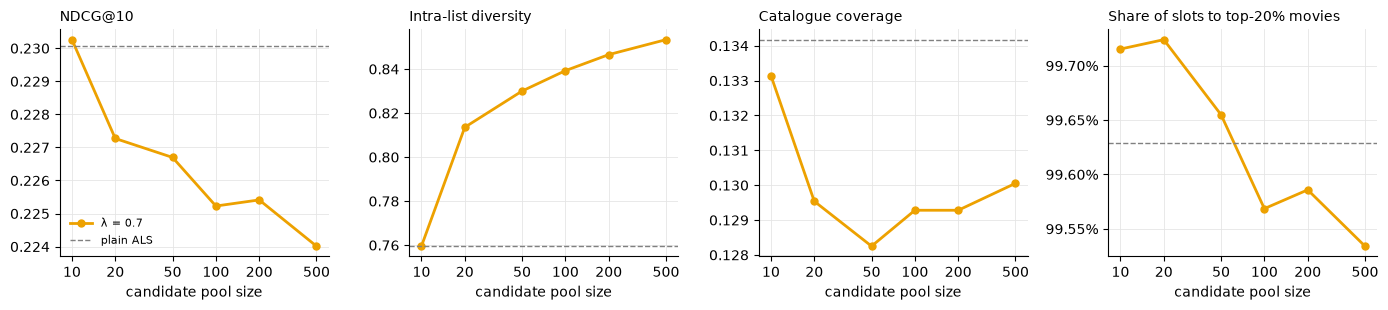

,ndcg,ild,coverage,gini,calibration_error,popular_share
pool_size,,,,,,
10,0.2303,0.7596,0.1331,0.9549,0.1623,0.9972
20,0.2273,0.8136,0.1295,0.9565,0.1432,0.9972
50,0.2267,0.8300,0.1283,0.9572,0.1406,0.9965
100,0.2252,0.8393,0.1293,0.9571,0.1395,0.9957
200,0.2254,0.8466,0.1293,0.9572,0.1381,0.9959
500,0.2240,0.8534,0.1301,0.9576,0.1376,0.9953


In [7]:
mmr = pool[pool["lambda"] == CHOSEN].set_index("pool_size")
base = test.loc[1.0]  # plain ALS does not depend on the pool size
panels = [("ndcg", "NDCG@10"), ("ild", "Intra-list diversity"), ("coverage", "Catalogue coverage"),
          ("popular_share", "Share of slots to top-20% movies")]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (metric, title) in zip(axes, panels):
    ax.plot(mmr.index, mmr[metric], marker="o", color=ALS, markersize=5, label="λ = 0.7")
    ax.axhline(base[metric], color="grey", linestyle="--", linewidth=1, label="plain ALS")
    ax.set_xscale("log")
    ax.set_xticks(mmr.index, [str(n) for n in mmr.index])
    ax.minorticks_off()
    ax.set_xlabel("candidate pool size")
    ax.set_title(title, loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
axes[3].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.2%}"))
plt.tight_layout()
save(fig, "pool_size")
plt.show()

mmr[["ndcg", "ild", "coverage", "gini", "calibration_error", "popular_share"]].round(4)

**What it shows**
- With a pool of 10, MMR only re-orders the ALS top 10, so ILD and coverage are those of plain ALS.
- Larger pools keep raising ILD (0.81 at 20 → 0.85 at 500) and slowly lowering NDCG, but **coverage stays at
  about 0.13 and the popular share at 99.5% for every pool size up to 500**.
- So the pool is *not* the reason coverage does not improve (the explanation notebook 05 left untested). Even
  among the ALS top 500 the genre-diverse movies are popular ones, and different users get the same "diverse"
  substitutes. To reduce popularity bias the re-ranker needs a popularity or exposure term (e.g. the
  exposure-aware re-ranker of slide 12), not only genres.

## Takeaways

| | |
|---|---|
| **Gained** | +10% intra-list diversity and −14% calibration error at λ = 0.7, both significant. |
| **Lost** | −2.1% NDCG@10 (significant, Holm p = 0.007), −0.5 pp catalogue coverage, slightly higher Gini. |
| **Not changed** | Popularity bias: 99.6% of slots go to the top-20% movies with and without MMR (still 97.5% at λ = 0). |
| **Who pays (users)** | Heavy users and users with broad taste lose the accuracy, and they also gain the most calibration. |
| **Who pays (items)** | Drama and Comedy lose slots to Adventure, Crime, Sci-Fi, Film-Noir and other rarer genres. Long-tail movies gain nothing. |
| **Shape** | Shallow from λ = 1 to 0.7 (λ = 0.9 and 0.8 cost no measurable accuracy), turns at about 0.4, and below 0.2 ILD saturates so only accuracy is lost. |

**Candidates for "one number we cannot explain":**
- Coverage at λ = 0.7 is *lower* than plain ALS (0.129 vs 0.134) although every list is more diverse. Our guess is
  that MMR replaces user-specific "more of the same genre" movies by the same handful of popular
  other-genre movies for many users; to check, count how many distinct movies enter and leave the lists.
- λ = 1 reproduces the Part 2 ALS test NDCG@10 exactly (0.2301), but coverage is 0.1342 instead of
  0.1331 in Part 2: 2 users without liked movies get all-zero ALS scores, and ALS breaks those ties differently
  for a top-10 and a top-100 request. This one we can explain.